# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import MSBCDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Original split

In [5]:
# specific bands
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/msbc/",
    "mode": "train",
    "imagery": "all",
    "selection": "bands",
    "bands_s2": ["B02","B03","B04","B08"],
    "bands_s1": ["VV"]
}
dataset = MSBCDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 3226


Total number of patches: 3226


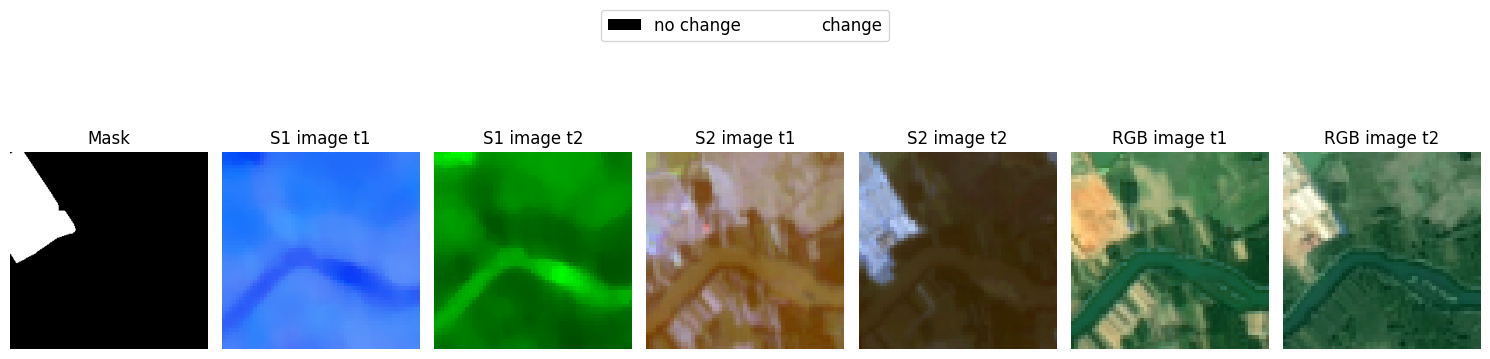

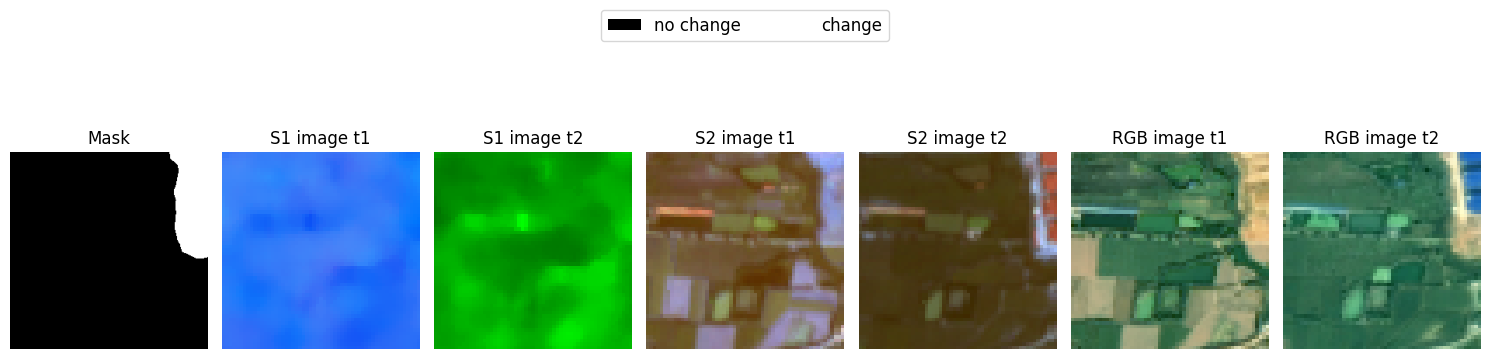

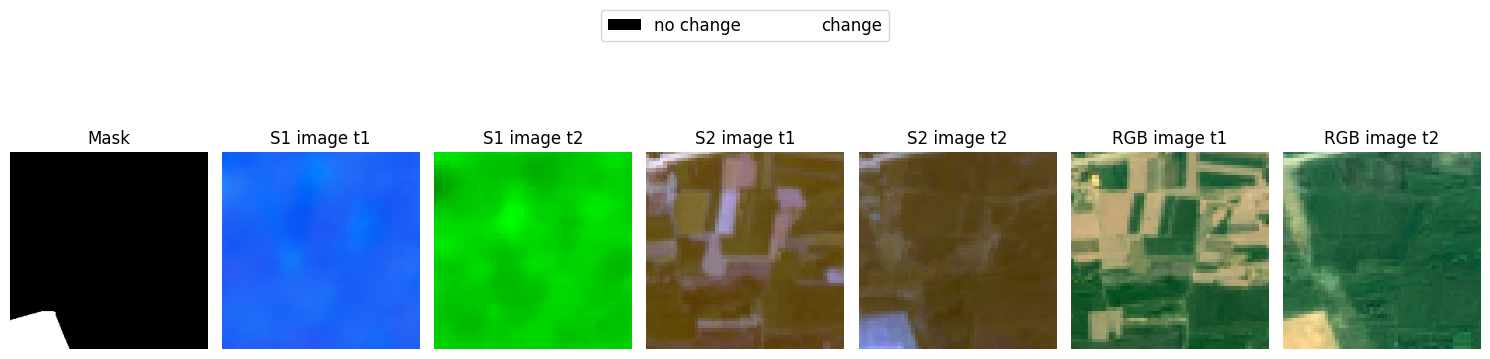

In [6]:
# rgb images
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/msbc/",
    "selection": "rgb",
    "mode": "train",
    "imagery": "all" # note: the aerial RGB image is resampled to the Sentinel image size
}
dataset = MSBCDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(1500);

Total number of patches: 3226


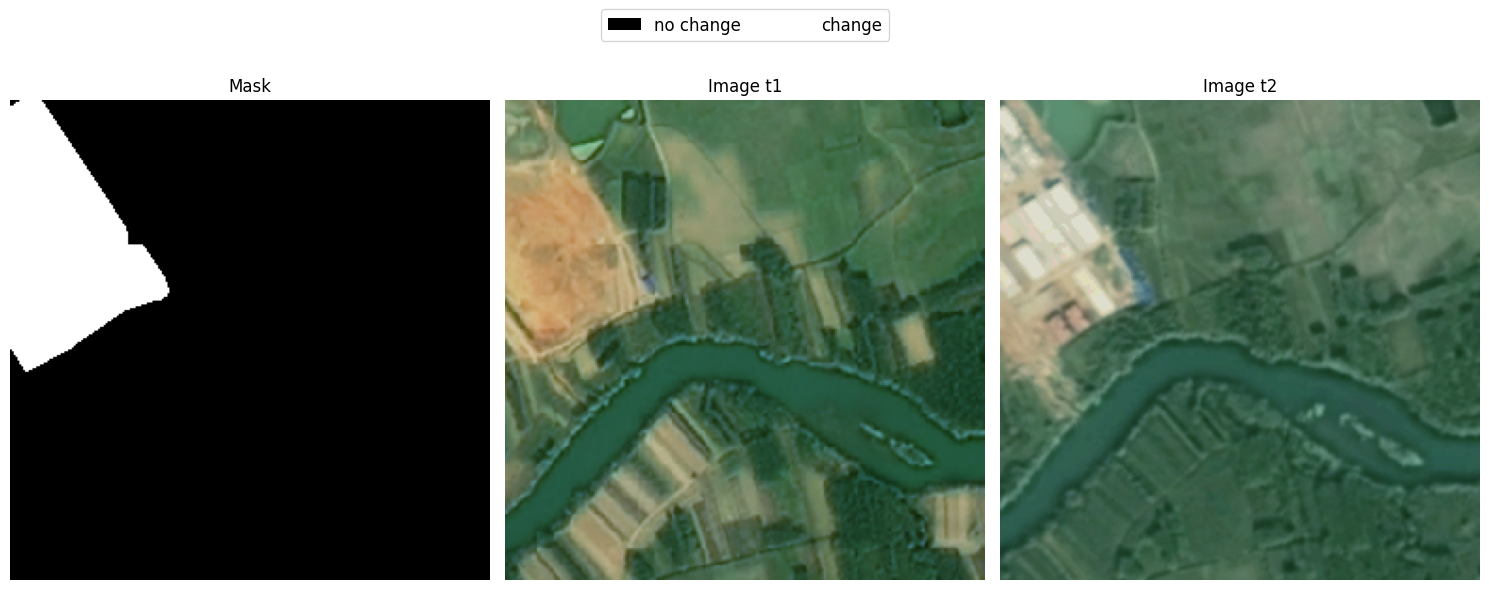

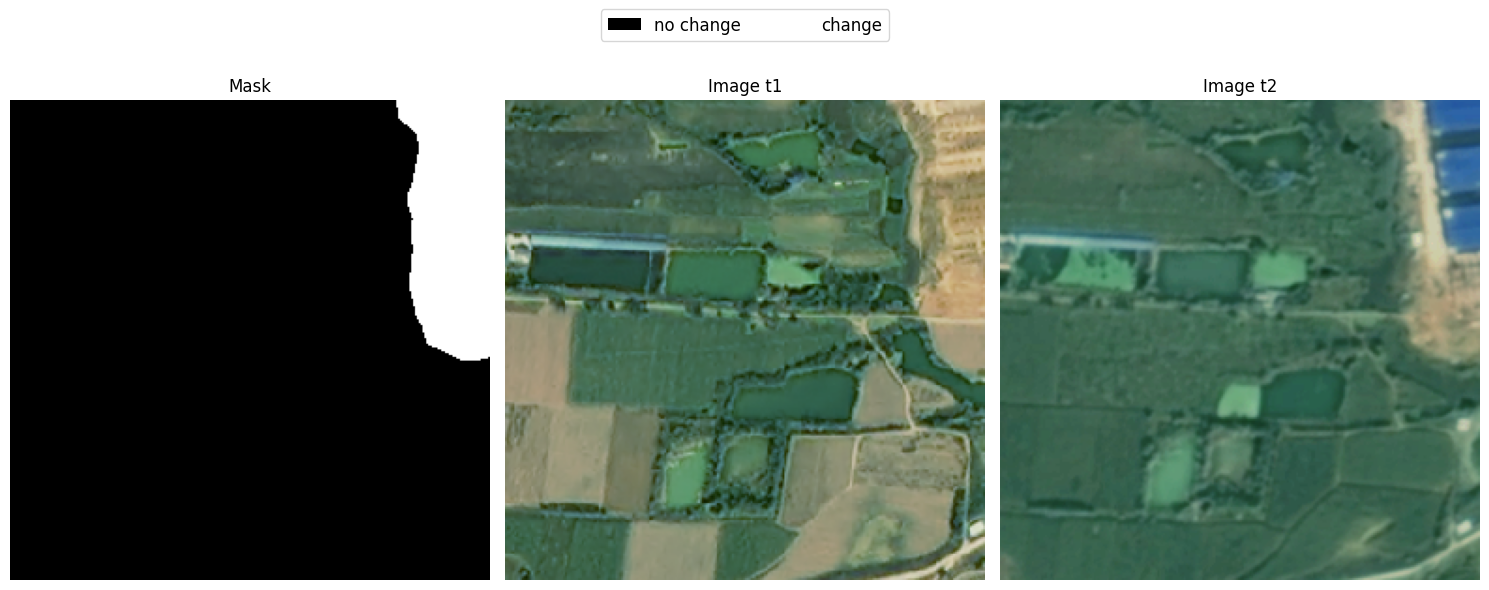

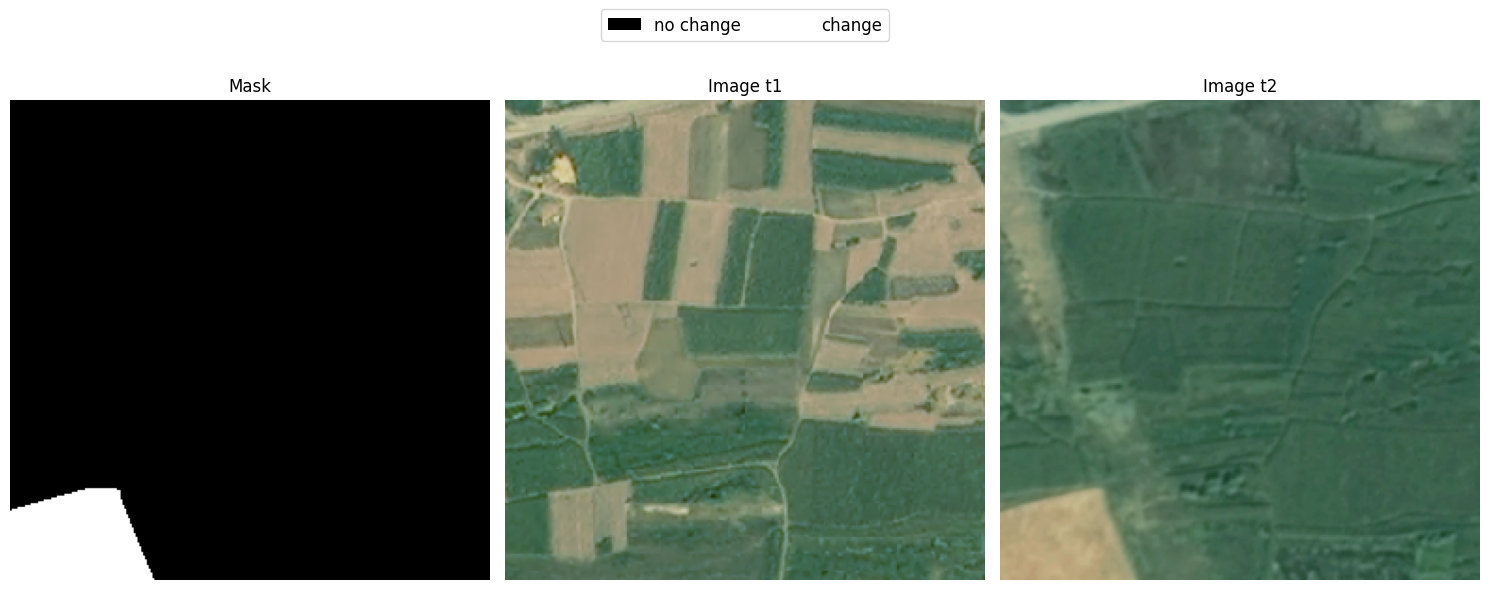

In [7]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/msbc/",
    "selection": "rgb",
    "mode": "train",
    "imagery": "aerial"
}
dataset = MSBCDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(1500);

In [8]:
dataset.data_distribution_table()

,Number of pixels
no change,196079867.0
change,15339269.0


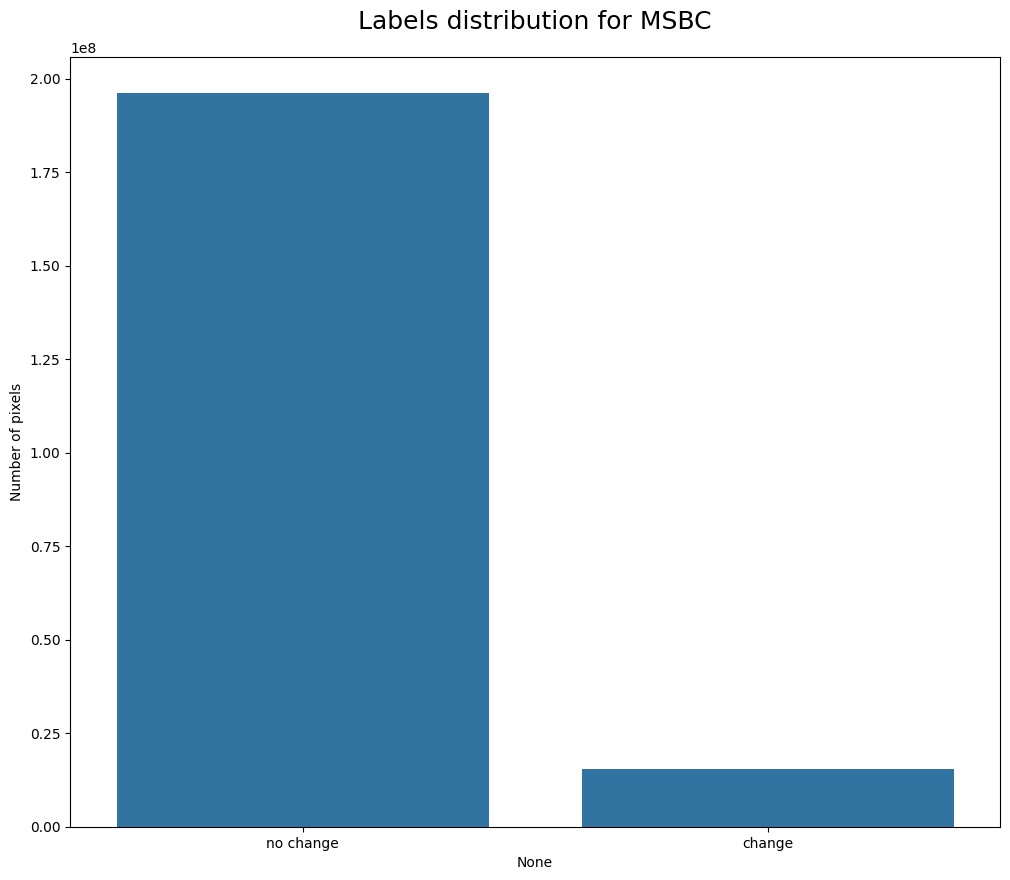

In [29]:
dataset.data_distribution_barchart();

New 60/20/20 split

Total number of patches: 2253


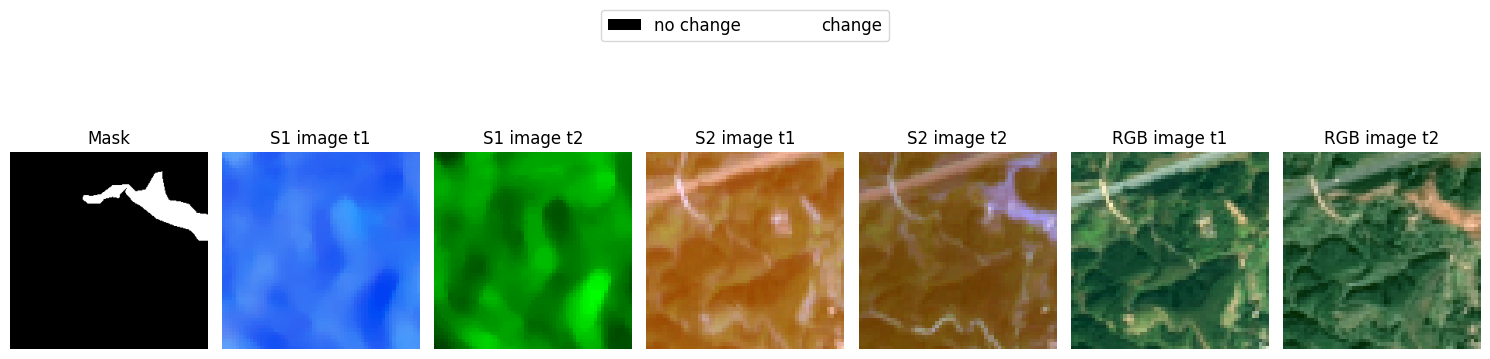

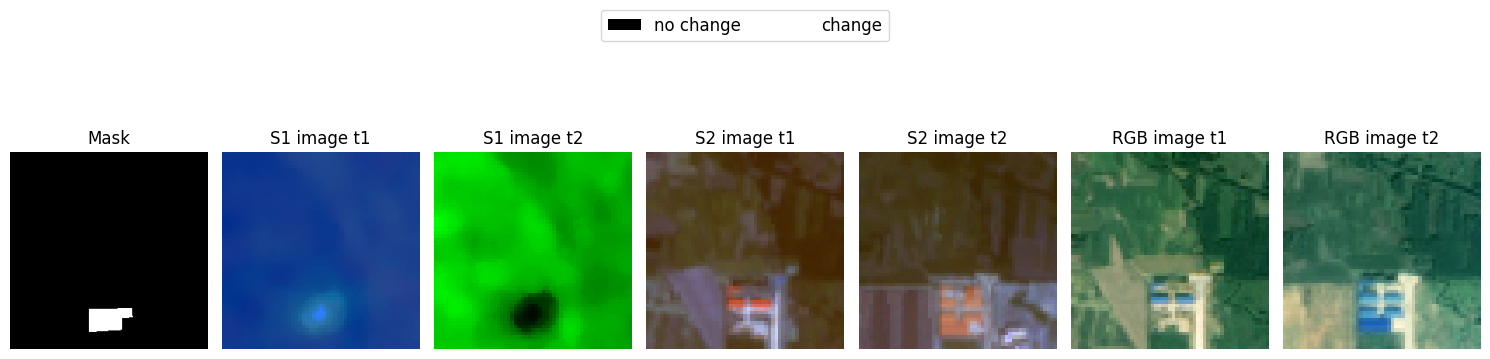

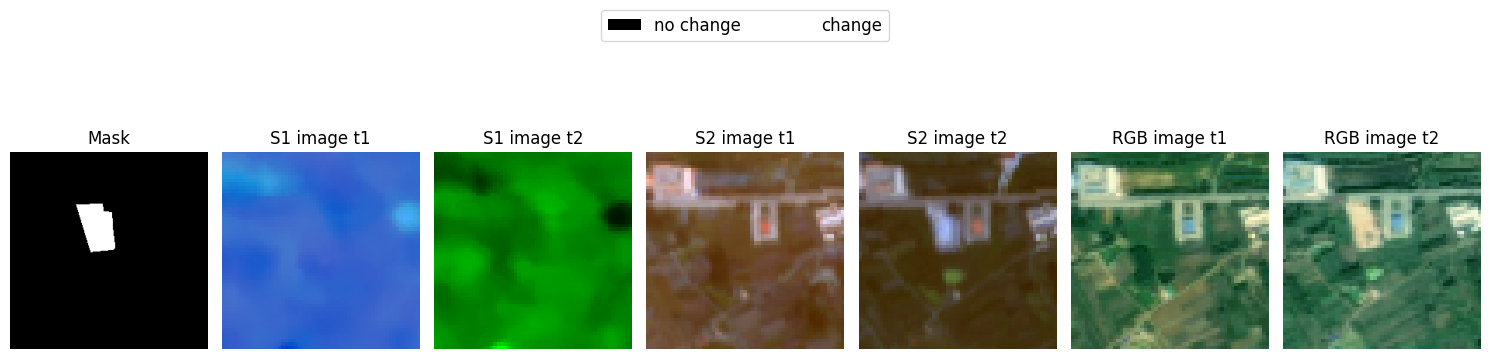

In [9]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/msbc/",
    "csv_file": "/home/dragik/data/FAIR_EO/msbc/msbc_train.csv",
    "selection": "rgb",
    "imagery": "all"
}
dataset = MSBCDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(1500);

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/msbc/",
    "csv_file": "/home/dragik/data/FAIR_EO/msbc/msbc_train.csv",
    "imagery": "aerial", # can be changed to s1, s2 or all
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = MSBCDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/msbc/",
    "csv_file": "/home/dragik/data/FAIR_EO/msbc/msbc_val.csv",
    "imagery": "aerial",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = MSBCDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(2253, 751)

## Create the model

In [30]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/msbc"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [17]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-29 08:15:15,201 INFO Starting training.
training: 100%|██████████| 141/141 [00:18<00:00,  7.79it/s]
2026-01-29 08:15:33,415 INFO epoch: 1, loss:  0.18463
testing on train set: 100%|██████████| 141/141 [00:14<00:00,  9.95it/s]
2026-01-29 08:15:48,824 INFO Accuracy:0.9485528694488078, Accuracy per Class:[0.94581557 0.95129017], Precision Micro:0.9561050447847904, Precision Macro:0.8127931449804944, Precision Weighted:0.9592898756484534, Precision per Class:[0.98361233 0.64197396], Recall Micro:0.9402738825988092, Recall Macro:0.835815248299763, Recall Weighted:0.9402738825988093, Recall per Class:[0.95761687 0.71401363], F1_score Micro:0.948123383624008, F1_score Macro:0.8232603542788341, F1_score Weighted:0.949483976940556, F1_score per Class:[0.97044054 0.67608016], IOU:0.9013636854962689, IOU mean:0.7266219617307199, IOU per Class:[0.94257844 0.51066548]
training: 100%|██████████| 141/141 [00:17<00:00,  8.10it/s]
2026-01-29 08:16:06,231 INFO epoch: 2, loss:  0.10468
testing on

## Predictions

2026-01-29 09:01:08,950 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/msbc/checkpoint.pth.tar
2026-01-29 09:01:10,207 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/msbc/checkpoint.pth.tar at epoch 51


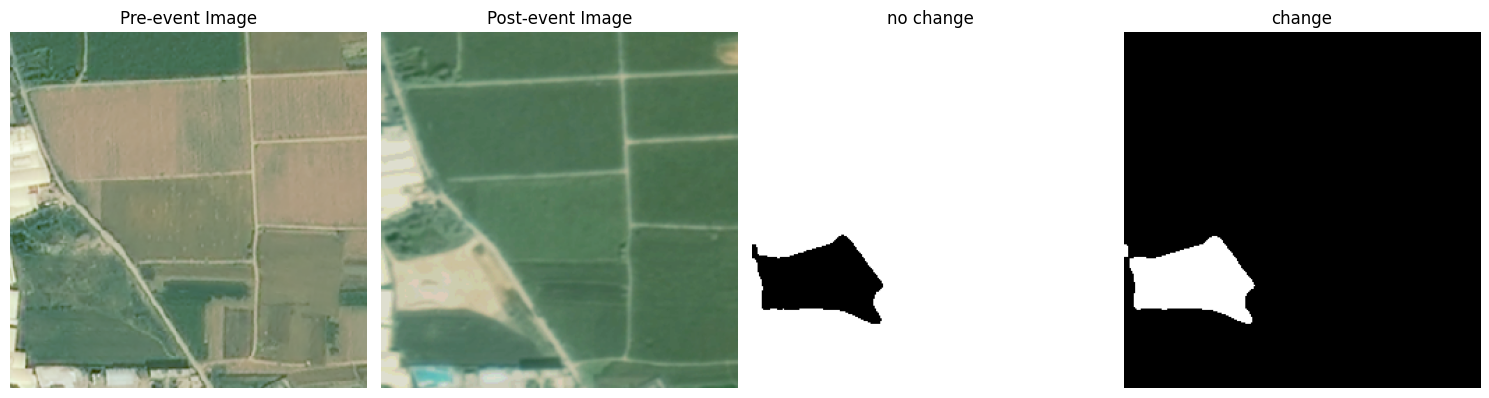

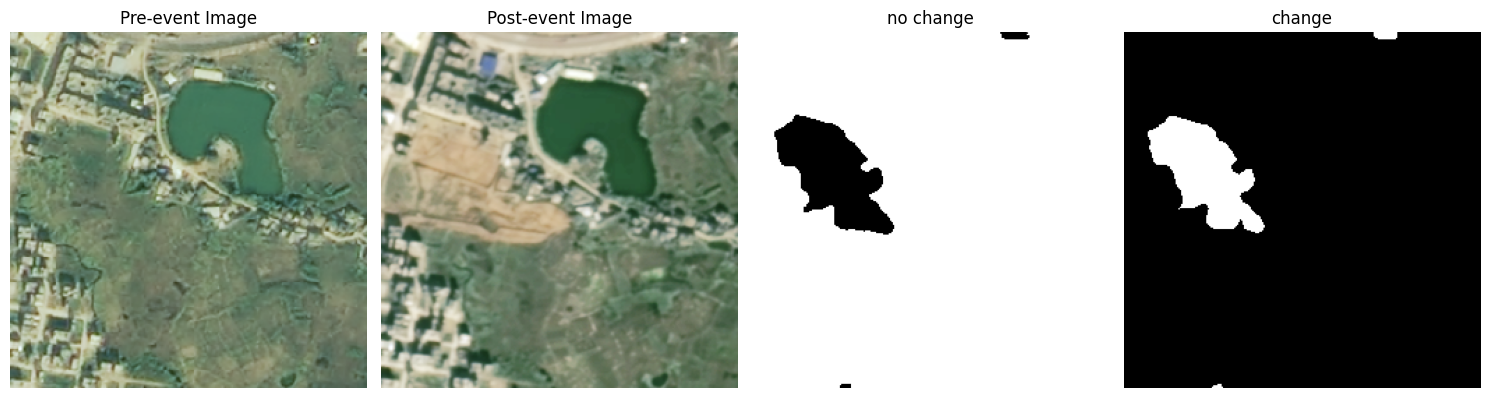

In [18]:
model_path = "/home/dragik/data/FAIR_EO/experiments/msbc/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("/home/dragik/data/FAIR_EO/msbc/train/rgb1/2614.tif")
image2 = image_loader("/home/dragik/data/FAIR_EO/msbc/train/rgb2/2614.tif")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("/home/dragik/data/FAIR_EO/msbc/test/rgb1/31.tif")
image2 = image_loader("/home/dragik/data/FAIR_EO/msbc/test/rgb2/31.tif")
fig = model.predict_masks(image1, image2, labels, transform)